# Methods for Unsupervised Clustering — Python companion
**Machine Learning for Biomedical Data (MLBD), Week 4**

This notebook follows the R lecture `lectures/week4/clustering.Rmd` section by section, replacing `hclust`/`cutree` with `scipy.cluster.hierarchy`, `kmeans` with scikit-learn's `KMeans`, `Mclust` with `GaussianMixture`, `dbscan` with `DBSCAN`, `igraph::cluster_leiden` with `leidenalg`, and `pheatmap` with seaborn's `clustermap`. It uses the same data as the R lecture.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore", message="Clustering large matrix")

# Data live in python/data/ in the course repo. If you're running this
# notebook somewhere else (e.g., Google Colab), it falls back to GitHub.
LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

## Look at your data first: boxplots
The tissue gene expression data: 189 samples, 500 genes, 7 tissues. Boxplots of the first four genes by tissue:

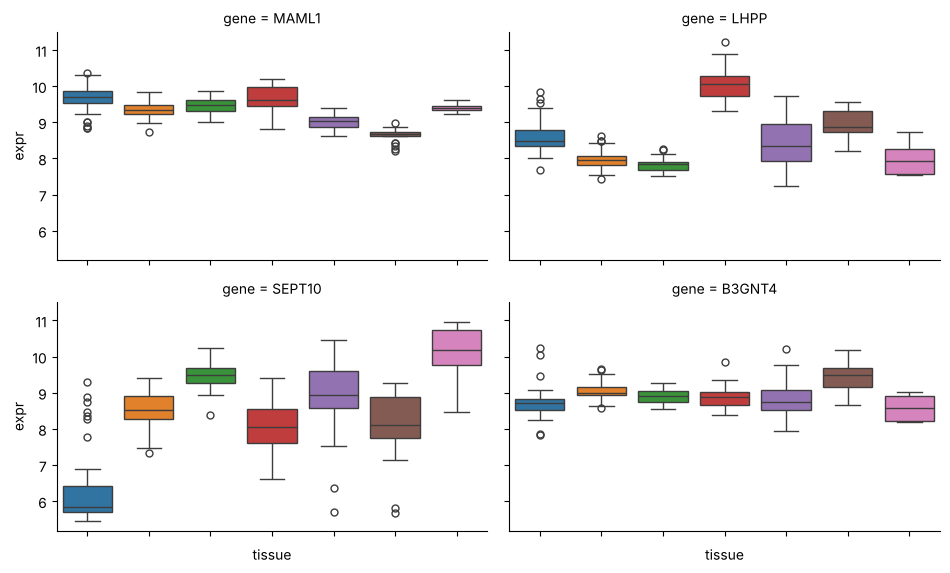

In [2]:
te = pd.read_csv(DATA + "tissue_gene_expression.csv")
tissue = te.pop("tissue")
long = te.iloc[:, :4].assign(tissue=tissue).melt(id_vars="tissue", var_name="gene", value_name="expr")

g = sns.catplot(data=long, x="tissue", y="expr", hue="tissue", col="gene",
                col_wrap=2, kind="box", height=3, aspect=1.6)
g.set_xticklabels([])
plt.show()

## Choosing a distance, and scaling
`scipy.spatial.distance.pdist` computes all pairwise distances:

| R | Python |
|---|---|
| `dist(x)` | `pdist(x)` (Euclidean) |
| `dist(x, method = "manhattan")` | `pdist(x, "cityblock")` |
| `as.dist(1 - cor(t(x)))` | `pdist(x, "correlation")` |
| `scale(x)` | `StandardScaler().fit_transform(x)` |

Note: `StandardScaler` divides by the population SD ($n$); R's `scale` uses $n-1$. The difference is negligible for clustering.

## Hierarchical clustering: movie ratings
Ratings of the top 50 movies, keeping users who rated at least 25 of them. Like the R code, we pivot to a movies × users matrix, then center each column (user) and each row (movie).

In [3]:
mv = pd.read_csv(DATA + "movielens_top50.csv")
mv = mv[mv.groupby("userId")["userId"].transform("size") >= 25]

x = mv.pivot_table(index="title", columns="userId", values="rating")
x = x.sub(x.mean(axis=0), axis=1)          # center users (columns)
x = x.sub(x.mean(axis=1), axis=0)          # center movies (rows)

# shorten titles, like str_remove(": Episode") + str_trunc(20) in R
x.index = [t.replace(": Episode", "") for t in x.index]
x.index = [t if len(t) <= 20 else t[:17] + "..." for t in x.index]
print(x.shape)
print(f"{x.isna().to_numpy().mean():.0%} of the matrix is missing")

(50, 139)
31% of the matrix is missing


### Missing data
R's `dist()` uses only the users who rated both movies, then rescales. scipy's `pdist` has no NA handling, so we write a small function that does the same thing as R.

In [4]:
def r_dist(m):
    # Euclidean distance like R's dist(): use pairs present in both rows,
    # then scale up by sqrt(p / number of pairs used)
    m = np.asarray(m, dtype=float)
    n, p = m.shape
    d = []
    for i in range(n - 1):
        diff = m[i] - m[i + 1:]
        ok = ~np.isnan(diff)
        ss = np.nansum(diff ** 2, axis=1)
        d.extend(np.sqrt(ss * p / ok.sum(axis=1)))
    return np.array(d)                      # condensed form, like pdist

d = r_dist(x)
h = linkage(d, method="complete")           # R's hclust() default

### Dendrogram

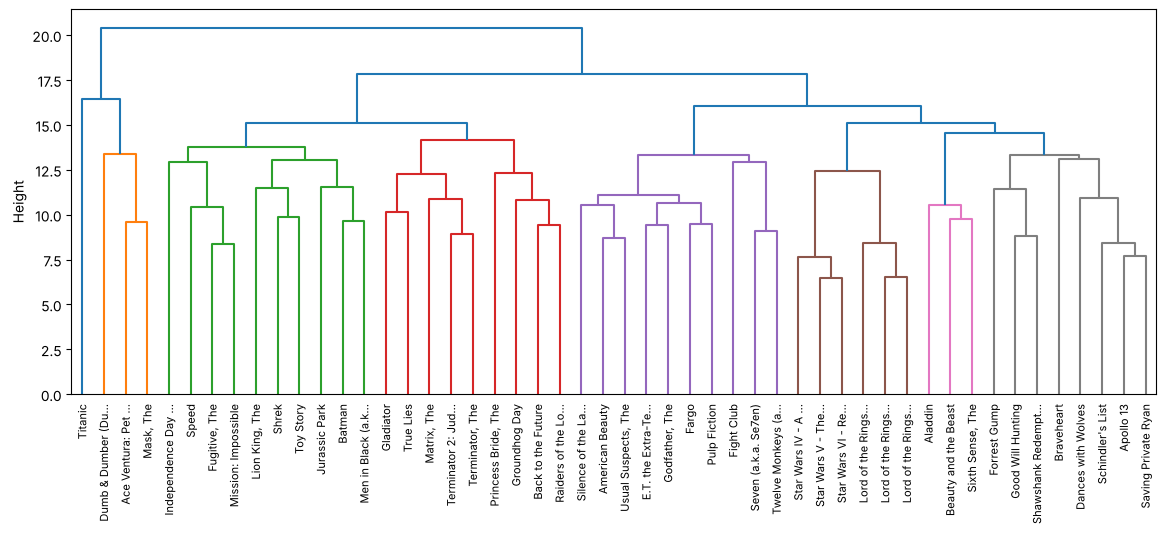

In [5]:
plt.figure(figsize=(14, 5))
dendrogram(h, labels=x.index.to_list(), leaf_font_size=8)
plt.ylabel("Height")
plt.show()

### Linkage
`method=` in `linkage` is the same idea as `method=` in `hclust`: `"complete"` (R's default), `"single"`, `"average"`, and `"ward"` (R's `ward.D2`). Ward linkage needs raw Euclidean data, so pass the data matrix rather than distances.

### Cutting the tree
`fcluster` plays the role of `cutree`: cut at a height (`criterion="distance"`) or ask for a number of groups (`criterion="maxclust"`).

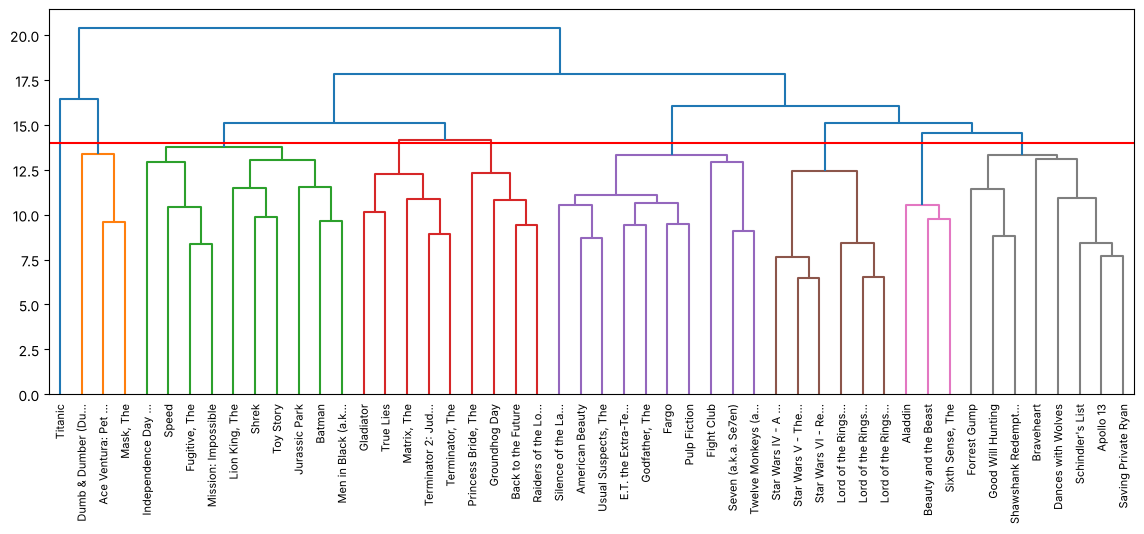

{1: 3, 2: 1, 3: 10, 4: 5, 5: 4, 6: 10, 7: 6, 8: 3, 9: 8}
{1: 3, 2: 1, 3: 4, 4: 6, 5: 5, 6: 4, 7: 10, 8: 6, 9: 3, 10: 8}


In [6]:
plt.figure(figsize=(14, 5))
dendrogram(h, labels=x.index.to_list(), leaf_font_size=8)
plt.axhline(14, color="red")
plt.show()

groups_h = fcluster(h, t=14, criterion="distance")   # cutree(h, h = 14)
print(pd.Series(groups_h).value_counts().sort_index().to_dict())

groups = pd.Series(fcluster(h, t=10, criterion="maxclust"), index=x.index)  # cutree(h, k = 10)
print(groups.value_counts().sort_index().to_dict())

### Interpreting groups
Group numbers are arbitrary, so find groups by a member:

In [7]:
def in_group(g, title):
    return list(g.index[g == g[title]])

for t in ["Star Wars IV - A ...", "Schindler's List", "Ace Ventura: Pet ..."]:
    print(in_group(groups, t))

['Lord of the Rings...', 'Lord of the Rings...', 'Lord of the Rings...', 'Star Wars IV - A ...', 'Star Wars V - The...', 'Star Wars VI - Re...']
['Apollo 13', 'Braveheart', 'Dances with Wolves', 'Forrest Gump', 'Good Will Hunting', 'Saving Private Ryan', "Schindler's List", 'Shawshank Redempt...']
['Ace Ventura: Pet ...', 'Dumb & Dumber (Du...', 'Mask, The']


### Clustering the raters
Same thing on the transpose: cluster users instead of movies.

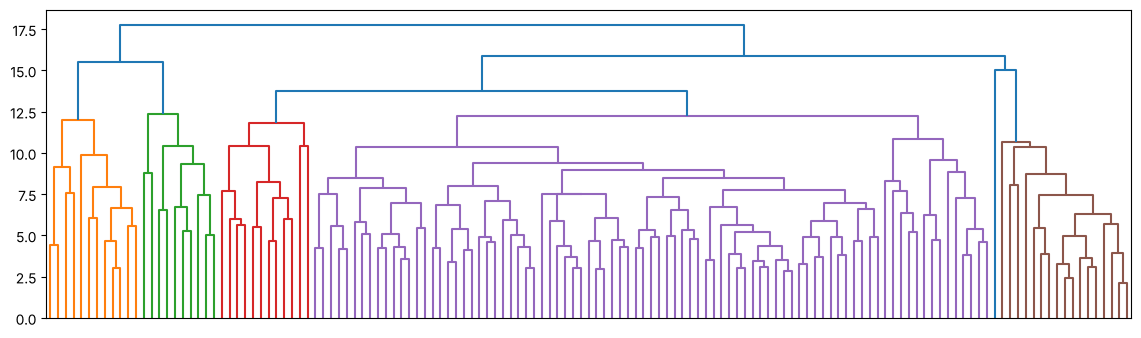

In [8]:
h_2 = linkage(r_dist(x.T), method="complete")
plt.figure(figsize=(14, 4))
dendrogram(h_2, no_labels=True)
plt.show()

## K-means
`KMeans` doesn't handle missing values either, so fill them with 0 like the R lecture. After centering, 0 means **mean imputation**. `n_init=25` is R's `nstart = 25`. Note: scikit-learn uses **k-means++** starting centers by default; R's `kmeans` uses random starts.

In [9]:
x_0 = x.fillna(0)
km = KMeans(n_clusters=10, n_init=25, random_state=0).fit(x_0)
groups = pd.Series(km.labels_ + 1, index=x.index)     # 1-based, like R
print(groups.value_counts().sort_index().to_dict())
for t in ["Star Wars IV - A ...", "Schindler's List", "Pulp Fiction"]:
    print(in_group(groups, t))

{1: 8, 2: 11, 3: 3, 4: 9, 5: 2, 6: 3, 7: 4, 8: 4, 9: 3, 10: 3}
['Star Wars IV - A ...', 'Star Wars V - The...', 'Star Wars VI - Re...']
['Braveheart', 'Dances with Wolves', 'Gladiator', 'Godfather, The', 'Good Will Hunting', 'Saving Private Ryan', "Schindler's List", 'Shawshank Redempt...']
['Fargo', 'Pulp Fiction', 'Silence of the La...']


## Choosing k: tissue data
Elbow plot (`inertia_` is the WCSS), mean silhouette width, and the gap statistic. scikit-learn has no gap statistic, so we write a short version: compare $\log(\text{WCSS})$ with its average over data simulated uniformly within the range of each feature (no clusters). Choose the smallest $k$ with $\text{Gap}(k) \ge \text{Gap}(k+1) - s_{k+1}$.

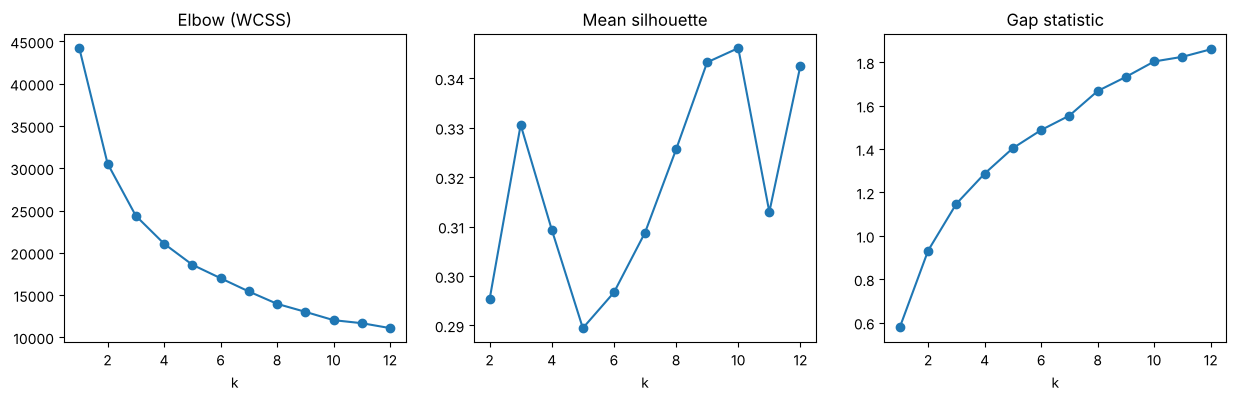

silhouette picks k = 10 ; gap picks k = 12 ; truth: 7


In [10]:
xt = te - te.mean(axis=0)                     # centered tissue data
ks = range(1, 13)
wcss = [KMeans(k, n_init=20, random_state=1).fit(xt).inertia_ for k in ks]
sil = [silhouette_score(xt, KMeans(k, n_init=20, random_state=1).fit_predict(xt)) for k in ks[1:]]

def gap_stat(X, ks, B=20, seed=1):
    rng = np.random.default_rng(seed)
    X = np.asarray(X); lo, hi = X.min(0), X.max(0)
    gaps, sks = [], []
    for k in ks:
        logw = np.log(KMeans(k, n_init=10, random_state=seed).fit(X).inertia_)
        ref = [np.log(KMeans(k, n_init=10, random_state=seed)
                      .fit(rng.uniform(lo, hi, X.shape)).inertia_) for _ in range(B)]
        gaps.append(np.mean(ref) - logw)
        sks.append(np.std(ref) * np.sqrt(1 + 1 / B))
    return np.array(gaps), np.array(sks)

gap, sk = gap_stat(xt, ks)
k_gap = next((k for i, k in enumerate(ks[:-1]) if gap[i] >= gap[i + 1] - sk[i + 1]),
             ks[-1])    # no k qualifies: gap still rising at k = 12

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(ks, wcss, "o-"); ax[0].set_title("Elbow (WCSS)")
ax[1].plot(ks[1:], sil, "o-"); ax[1].set_title("Mean silhouette")
ax[2].errorbar(ks, gap, yerr=sk, fmt="o-"); ax[2].set_title("Gap statistic")
for a in ax: a.set_xlabel("k")
plt.show()
print("silhouette picks k =", ks[1:][int(np.argmax(sil))], "; gap picks k =", k_gap, "; truth: 7")

As in R, the criteria disagree with each other and with the 7 tissues. (Exact values differ from R because the random starts and reference data differ.)

## Checking clusters against known labels
Cross-tabulate, and compute the adjusted Rand index (R: `mclust::adjustedRandIndex`):

In [11]:
km7 = KMeans(n_clusters=7, n_init=25, random_state=1).fit_predict(xt) + 1
print(pd.crosstab(km7, tissue, rownames=["cluster"]))
print("ARI:", round(adjusted_rand_score(tissue, km7), 3))

tissue   cerebellum  colon  endometrium  hippocampus  kidney  liver  placenta
cluster                                                                      
1                33      0            0            0       0      0         0
2                 0     34            0            0       0      0         0
3                 0      0            0            0      39      0         0
4                 0      0            0            0       0     26         0
5                 5      0            0           31       0      0         0
6                 0      0           15            0       0      0         0
7                 0      0            0            0       0      0         6
ARI: 0.934


## Gaussian mixture models: Old Faithful
`mclust` chooses the number of components and the covariance shape by BIC. In scikit-learn we loop over both and keep the lowest BIC. (scikit-learn's BIC is lower-is-better; mclust's is higher-is-better, same idea.)

components: 2 | covariance: full


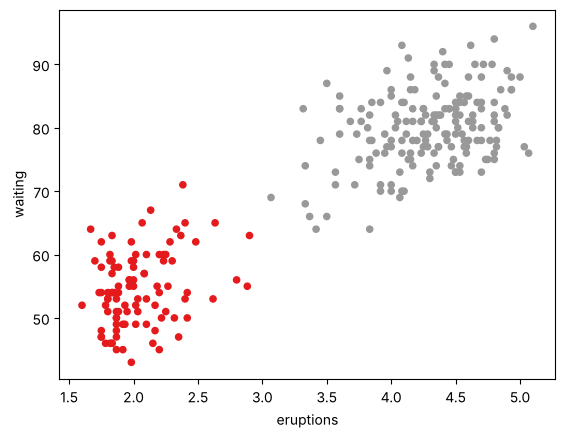

In [12]:
faithful = pd.read_csv(DATA + "faithful.csv")
fits = [GaussianMixture(k, covariance_type=cv, random_state=0).fit(faithful)
        for k in range(1, 7) for cv in ["full", "tied", "diag", "spherical"]]
best = min(fits, key=lambda f: f.bic(faithful))
print("components:", best.n_components, "| covariance:", best.covariance_type)

lab = best.predict(faithful)
plt.scatter(faithful.eruptions, faithful.waiting, c=lab, cmap="Set1", s=20)
plt.xlabel("eruptions"); plt.ylabel("waiting")
plt.show()

Here BIC picks 2 components, while R's `mclust` picked 3: the two packages search different covariance families. Either is defensible, and that's the point: model selection depends on the model family.

Soft assignments: the probability of each component for each point (R: `fit$z`).

In [13]:
z = best.predict_proba(faithful)
print(np.round(z[:6], 3))
print("points with >10% uncertainty:", int(((1 - z.max(axis=1)) > 0.1).sum()))

[[0.    1.   ]
 [1.    0.   ]
 [0.    1.   ]
 [1.    0.   ]
 [0.    1.   ]
 [0.993 0.007]]
points with >10% uncertainty: 1


## DBSCAN vs. k-means
Two interleaved half-moons: k-means cuts them in half; DBSCAN follows the shapes. In scikit-learn, `min_samples` counts the point itself (like R's `minPts`) and noise points get label $-1$.

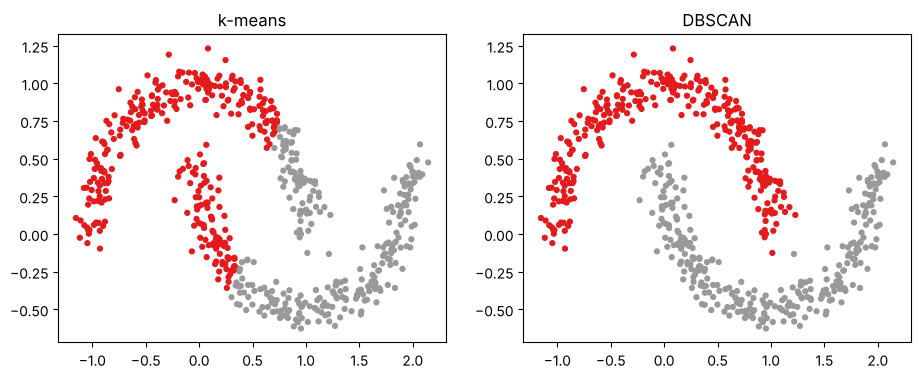

In [14]:
rng = np.random.default_rng(2)
t = rng.uniform(0, np.pi, 300)
moons = np.vstack([np.column_stack([np.cos(t), np.sin(t)]),
                   np.column_stack([1 - np.cos(t), 0.5 - np.sin(t)])])
moons += rng.normal(scale=0.08, size=moons.shape)

km = KMeans(2, n_init=10, random_state=0).fit_predict(moons)
db = DBSCAN(eps=0.2, min_samples=5).fit_predict(moons)    # -1 = noise

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(*moons.T, c=km, cmap="Set1", s=12); ax[0].set_title("k-means")
ax[1].scatter(*moons.T, c=db, cmap="Set1", s=12); ax[1].set_title("DBSCAN")
plt.show()

## Leiden clustering
Build a 10-nearest-neighbor graph on the top 20 PCs, then run Leiden (modularity) with `igraph` + `leidenalg` (`pip install igraph leidenalg`). Results differ a bit from R's `cluster_leiden`.

In [15]:
import igraph as ig
import leidenalg
from sklearn.neighbors import NearestNeighbors

pcs = PCA(n_components=20).fit_transform(xt)
nn = NearestNeighbors(n_neighbors=11).fit(pcs).kneighbors(pcs, return_distance=False)[:, 1:]
edges = [(i, j) for i in range(len(pcs)) for j in nn[i]]
g = ig.Graph(n=len(pcs), edges=edges).simplify()

part = leidenalg.find_partition(g, leidenalg.ModularityVertexPartition, seed=1)
cl = np.array(part.membership) + 1
print(pd.crosstab(cl, tissue, rownames=["cluster"]))
print("ARI:", round(adjusted_rand_score(tissue, cl), 3))

tissue   cerebellum  colon  endometrium  hippocampus  kidney  liver  placenta
cluster                                                                      
1                 0     34            0            0       0      0         6
2                 5      0            0           31       0      0         0
3                32      0            0            0       0      0         0
4                 0      0            0            0       0     26         0
5                 1      0            0            0      21      0         0
6                 0      0            0            0      18      0         0
7                 0      0           15            0       0      0         0
ARI: 0.799


## Heatmaps
Cluster rows and columns, and plot the reordered matrix, like `image(x[h_1$order, h_2$order])`:

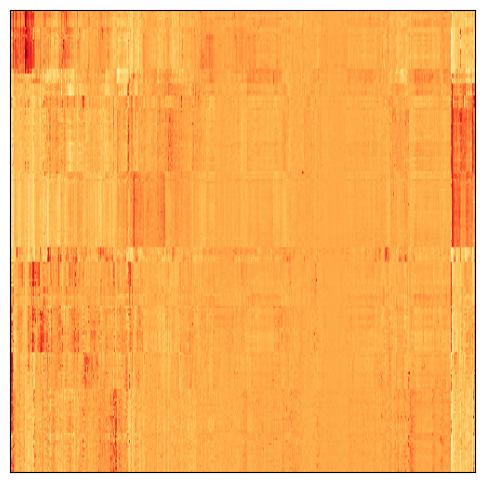

In [16]:
h_1 = linkage(xt, method="complete")
h_2 = linkage(xt.T, method="complete")
o1 = dendrogram(h_1, no_plot=True)["leaves"]
o2 = dendrogram(h_2, no_plot=True)["leaves"]

plt.figure(figsize=(6, 6))
plt.imshow(xt.iloc[o1, o2], aspect="auto", cmap="YlOrRd")
plt.xticks([]); plt.yticks([])
plt.show()

`sns.clustermap` does it all for us, like `pheatmap`, with the rows annotated by tissue. Like `pheatmap(scale = "none")`, `clustermap` does not rescale unless you set `standard_scale` or `z_score`.

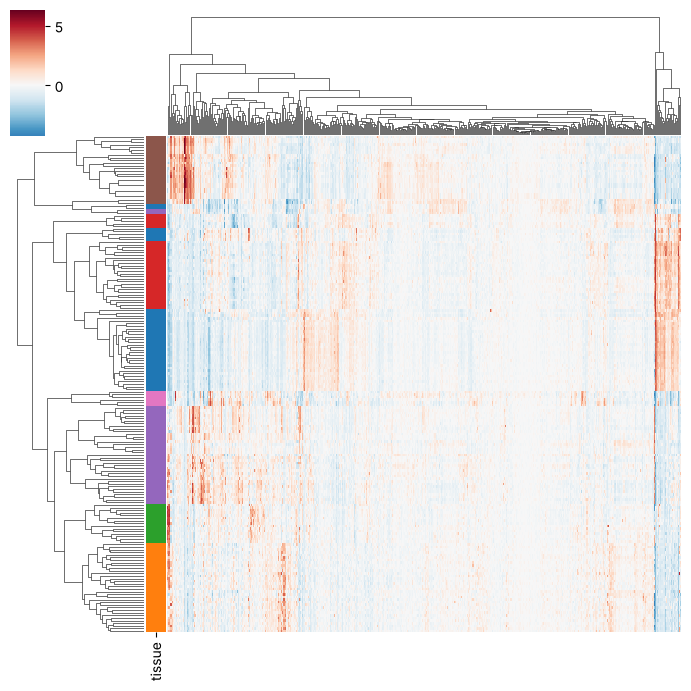

In [17]:
pal = dict(zip(tissue.unique(), sns.color_palette("tab10", tissue.nunique())))
sns.clustermap(xt, method="complete", cmap="RdBu_r", center=0, row_colors=tissue.map(pal),
               xticklabels=False, yticklabels=False, figsize=(7, 7))
plt.show()

## Filtering features
Keep the 25 genes with the highest standard deviation:

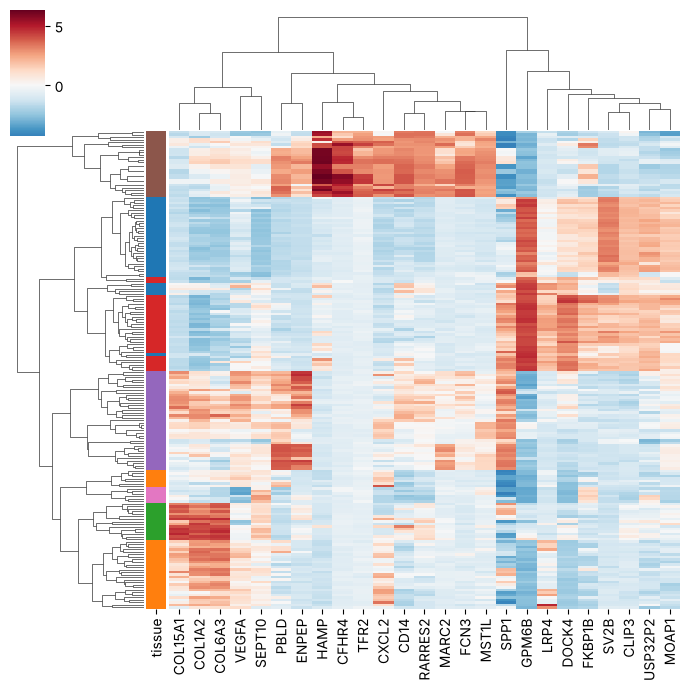

In [18]:
top25 = xt.std(axis=0).sort_values(ascending=False).index[:25]
sns.clustermap(xt[top25], method="complete", cmap="RdBu_r", center=0, row_colors=tissue.map(pal),
               yticklabels=False, figsize=(7, 7))
plt.show()